In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Preparation

In [2]:
df = pd.read_csv('../data/course_lead_scoring_2026.csv')

In [8]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [9]:
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

In [11]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [14]:
df.isnull().sum(
)

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [31]:
categorical = list(df.dtypes[df.dtypes == 'str'].index)

In [32]:
categorical

['lead_source', 'industry', 'employment_status', 'location']

In [33]:
for c in categorical:
    df[c] = df[c].str.lower().str.replace(' ', '_').fillna('NA')


df[numerical] = df[numerical].fillna(0.0)

In [36]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

## Validation Framework

In [37]:
from sklearn.model_selection import train_test_split

In [38]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [46]:
from sklearn.metrics import roc_auc_score

In [52]:
for n in numerical:
    score = roc_auc_score(df_train.converted, df_train[n])
    print(n, round(score, 3))


annual_income 0.608
number_of_courses_viewed 0.723
interaction_count 0.765
lead_score 0.788


In [53]:
df_train[numerical].corrwith(df_train.converted)

annual_income               0.188436
number_of_courses_viewed    0.394995
interaction_count           0.452813
lead_score                  0.484172
dtype: float64

### Q1: lead_score


In [64]:
from sklearn.feature_extraction import DictVectorizer

In [65]:
from sklearn.linear_model import LogisticRegression

In [66]:
dv = DictVectorizer(sparse=False)

In [67]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

In [156]:
def train(df_train, y_train, C):
    dicts = df_train[numerical + categorical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [157]:
def predict(df, dv, model):
    dicts = df[numerical + categorical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [70]:
y_train = df_train.converted.values
y_val = df_val.converted.values

In [71]:
dv, model = train(df_train, y_train)

In [72]:
y_pred = predict(df_val, dv, model)

In [75]:
round(roc_auc_score(y_val, y_pred), 3)

0.732

### Q2: 0.732

In [89]:
thresholds = np.arange(0, 1.01, 0.01)

In [82]:
def confusion_matrix(y_val, y_pred, t):
    tp = ((y_val == 1) & (y_pred >= t)).sum()
    tn = ((y_val == 0) & (y_pred < t)).sum()

    fp = ((y_val == 0) & (y_pred >= t)).sum()
    fn = ((y_val == 1) & (y_pred < t)).sum()
    
    return tp, tn, fp, fn

In [86]:
def precision(tp, fp):
    return tp / (tp + fp) if (tp + fp) > 0 else 0

In [87]:
def recall(tp, fn):
    return tp / (tp + fn)

In [90]:
precisions = []
recalls = []

for t in thresholds:
    tp, tn, fp, fn = confusion_matrix(y_val, y_pred, t)
    precisions.append(precision(tp, fp))
    recalls.append(recall(tp, fn))

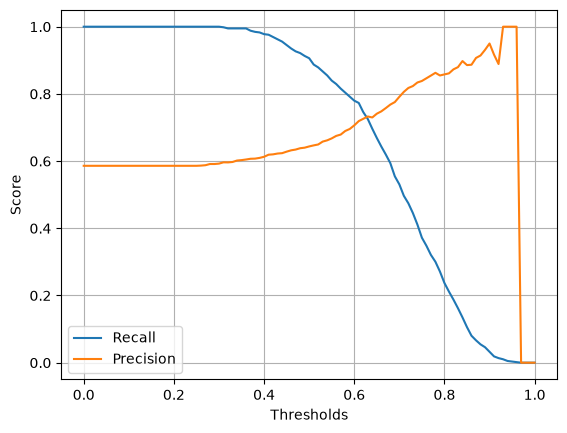

In [97]:
plt.plot(thresholds, recalls, label='Recall')
plt.plot(thresholds, precisions, label='Precision')

plt.xlabel('Thresholds')
plt.ylabel('Score')
plt.legend()
plt.grid()

plt.show()

In [114]:
diff = abs(np.array(precisions) - np.array(recalls))

In [119]:
valid = (np.array(precisions) != 0) | (np.array(recalls) != 0)

In [120]:
best_idx = np.argmin(np.where(valid, diff, np.inf))

In [121]:
print("Threshold:", thresholds[best_idx])
print("Precision:", precisions[best_idx])
print("Recall:", recalls[best_idx])

Threshold: 0.63
Precision: 0.7327586206896551
Recall: 0.7252559726962458


### Q3: 0.63

In [122]:
precisions = np.array(precisions)
recalls = np.array(recalls)

In [130]:
F1s = np.divide(
    2 * precisions * recalls,
    precisions + recalls,
    out=np.zeros_like(precisions, dtype=float),
    where=(precisions + recalls) != 0
    )

In [135]:
idx = np.argmax(F1s)

In [136]:
thresholds[idx]

np.float64(0.41000000000000003)

In [137]:
print("Threshold:", thresholds[idx])
print("F1:", F1s[idx])

Threshold: 0.41000000000000003
F1: 0.7576158940397352


### Q4: 0.41

In [138]:
from sklearn.model_selection import KFold

In [139]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [140]:
aucs = []
for train_idx,val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)
    auc = roc_auc_score(y_val, y_pred)
    aucs.append(auc)

In [143]:
aucs = np.array(aucs)

In [153]:
mean = aucs.mean()
std = aucs.std()
print(f"auc_mean: {mean.round(3)}, auc_std: {std.round(3)}")

auc_mean: 0.732, auc_std: 0.007


### Q5: 0.007

In [159]:
for c in [0.000001, 0.001, 1]:
    aucs = []
    for train_idx,val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=c)
        y_pred = predict(df_val, dv, model)
        auc = roc_auc_score(y_val, y_pred)
        aucs.append(auc)

    aucs = np.array(aucs)
    mean = aucs.mean()
    std = aucs.std()
    print(f"C: {c}, auc_mean: {mean.round(3)}, auc_std: {std.round(3)}")


C: 1e-06, auc_mean: 0.617, auc_std: 0.019
C: 0.001, auc_mean: 0.749, auc_std: 0.01
C: 1, auc_mean: 0.732, auc_std: 0.007


### Q6: 0.001